# A. Persiapan Data

## A1. Menyiapkan Dependensi

Memasang dependensi yang dibutuhkan untuk mengunduh data, mengolah tabel dan gambar, serta menjalankan dan memvisualisasikan model YOLO.

In [1]:
%pip install -q gdown matplotlib ultralytics pandas numpy pillow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.4 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


## A2. Mengunduh Dataset

Mengunduh arsip dataset dari Google Drive ke file `dataset.zip` menggunakan `gdown`.

In [2]:
!gdown -q "1CAPmwVmYW6499Ic1wx8TFptLV8beDZcX" -O dataset.zip

## A3. Mengekstrak Dataset

Mengekstrak `dataset.zip` ke folder `dataset_raw/` agar berkas gambar dan anotasi dapat diproses.

In [3]:
!unzip -q dataset.zip -d dataset_raw/

# B. Preprocessing Dataset

## B1. Menyeragamkan Kategori COCO

Menyeragamkan nama 11 kelas pada anotasi COCO untuk split train, valid, dan test. ID kategori dipetakan ke daftar kelas baru, anotasi yang tidak cocok dengan pemetaan dilewati, lalu file JSON diperbarui.

In [ ]:
import json
from pathlib import Path

Folder_awal = Path("/kaggle/working/dataset_raw/Telepati 8.0 Datasets") #ubah bagian ini dengan path di lokal anda misalnya 

splits = ["train", "valid", "test"]

Kategori_baru = [
    {"id": 1, "name": "bacterial_leaf_blight"},
    {"id": 2, "name": "bacterial_panicle_blight"},
    {"id": 3, "name": "blast"},
    {"id": 4, "name": "brown_spot"},
    {"id": 5, "name": "false_smut"},
    {"id": 6, "name": "healthy"},
    {"id": 7, "name": "leaf_roller"},
    {"id": 8, "name": "leaf_scald"},
    {"id": 9, "name": "narrow_brown"},
    {"id": 10, "name": "sheath_blight"},
    {"id": 11, "name": "tungro"},
]

Data_baru = {cat["name"]: cat["id"] for cat in Kategori_baru}

Mapping = {
    # Bacterial Leaf Blight
    "Bacterial leaf blight": "bacterial_leaf_blight",
    "bacterial_leaf_blight": "bacterial_leaf_blight",  # yang kaya gini cuma buat mastiin
    # Bacterial Panicle Blight
    "Bacterial panicle Blight": "bacterial_panicle_blight",
    "bacterial_panicle_blight": "bacterial_panicle_blight",
    # Blast
    "Blast": "blast",
    "Infected Blast": "blast",
    "Leaf blast": "blast",
    "blast": "blast",
    # Brown Spot
    "BrownSpot": "brown_spot",
    "Brown spot": "brown_spot",
    "brown_spot": "brown_spot",
    # False Smut
    "False-Smut": "false_smut",
    "false_smut": "false_smut",
    # Healthy
    "Healthy": "healthy",
    "Healthy Rice Leaf": "healthy",
    "Healthy Rice beads": "healthy",
    "healthy": "healthy",
    # Leaf Scald
    "Leaf Scald": "leaf_scald",
    "Leaf scald": "leaf_scald",
    "leaf_scald": "leaf_scald",
    # Leaf Roller
    "Leaf-roller": "leaf_roller",
    "leaf_roller": "leaf_roller",
    # Narrow Brown Spot
    "Narrow brown": "narrow_brown",
    "narrow_brown": "narrow_brown",
    # Rice Tungro
    "Rice-Tungro": "tungro",
    "tungro": "tungro",
    # Sheath Blight
    "Sheath Blight": "sheath_blight",
    "sheath_blight": "sheath_blight",
}

for split in splits:
    file_json = Folder_awal / split / "_annotations.coco.json"
    if not file_json.exists():
        print(f"File gaada di: {file_json}")
        continue

    with open(file_json, "r", encoding="utf-8") as f:
        data = json.load(f)

    raw_ke_data_baru = {}
    kategori_asli = data.get("categories", [])

    # 1. LOOP UNTUK MEMBUAT PEMETAAN (MAPPING) ID
    for cat in kategori_asli:
        id_lama = cat["id"]
        nama_lama = cat["name"]
        if nama_lama in Mapping:
            nama_baru = Mapping[nama_lama]
            id_baru = Data_baru[nama_baru]
            raw_ke_data_baru[id_lama] = id_baru
            print(
                f"  ID Lama {id_lama}:({nama_lama}) diubah ke :{id_baru}: ({nama_baru})"
            )
        else:
            print(f"  ID Lama {id_lama} : ({nama_lama}) diabaikan")

    # 2. UPDATE DAFTAR KATEGORI HANYA DENGAN 11 KELAS BARU
    data["categories"] = Kategori_baru

    # 3. UPDATE ANOTASI
    annotations_baru = []
    total_anotasi_asli = len(data.get("annotations", []))

    for ann in data.get("annotations", []):
        id_lama = ann["category_id"]
        if id_lama in raw_ke_data_baru:
            ann["category_id"] = raw_ke_data_baru[id_lama]
            annotations_baru.append(ann)

    data["annotations"] = annotations_baru

    print(
        f"\nJumlah Anotasi Awal: {total_anotasi_asli} , Jumlah anotasi baru: {len(annotations_baru)}"
    )

    # 4. SIMPAN PERUBAHAN KE FILE JSON 
    with open(file_json, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2)

    print(f"File berhasil diperbarui di: {file_json}")

  ID Lama 0 : (Leaf-blight) diabaikan
  ID Lama 1:(Bacterial panicle Blight) diubah ke :2: (bacterial_panicle_blight)
  ID Lama 2:(False-Smut) diubah ke :5: (false_smut)
  ID Lama 3:(Healthy Rice Leaf) diubah ke :6: (healthy)
  ID Lama 4:(Healthy Rice beads) diubah ke :6: (healthy)
  ID Lama 5:(Infected Blast) diubah ke :3: (blast)
  ID Lama 6:(Leaf-roller) diubah ke :7: (leaf_roller)
  ID Lama 7 : (Rice-Leaf-Diseasee) diabaikan
  ID Lama 8:(Blast) diubah ke :3: (blast)
  ID Lama 9:(BrownSpot) diubah ke :4: (brown_spot)
  ID Lama 10:(Healthy) diubah ke :6: (healthy)
  ID Lama 11:(Leaf Scald) diubah ke :8: (leaf_scald)
  ID Lama 12:(Rice-Tungro) diubah ke :11: (tungro)
  ID Lama 13:(Sheath Blight) diubah ke :10: (sheath_blight)
  ID Lama 14 : (paddy) diabaikan
  ID Lama 15:(Bacterial leaf blight) diubah ke :1: (bacterial_leaf_blight)
  ID Lama 16:(Brown spot) diubah ke :4: (brown_spot)
  ID Lama 17:(Leaf blast) diubah ke :3: (blast)
  ID Lama 18:(Leaf scald) diubah ke :8: (leaf_scald)
 

## B2. Memeriksa Anotasi COCO

Memeriksa hasil penyeragaman anotasi COCO untuk setiap split dengan menghitung jumlah kategori dan bounding box per kelas.

In [ ]:
import json
from collections import Counter
from pathlib import Path


for split in splits:
    file_json = Folder_awal / split / "_annotations.coco.json"

    if not file_json.exists():
        print(f"File tidak ditemukan: {file_json}")
        continue

    with open(file_json, "r", encoding="utf-8") as f:
        data = json.load(f)

    # 1. Ambil pemetaan ID ke Nama Kelas dari daftar 'categories'
    categories = data.get("categories", [])
    id_to_name = {cat["id"]: cat["name"] for cat in categories}

    # 2. Hitung kemunculan masing-masing ID kelas di daftar 'annotations'
    annotations = data.get("annotations", [])
    counter = Counter(ann["category_id"] for ann in annotations)

    print(f"\n==================================================")
    print(f" VERIFIKASI SPLIT: {split.upper()}")
    print(f"==================================================")
    print(f"Total Jenis Kelas Terdaftar : {len(categories)}")
    print(f"Total Anotasi (Bounding Box): {len(annotations)}")
    print("-" * 50)
    print(f"{'ID':<5} | {'Nama Kelas':<25} | {'Jumlah Anotasi'}")
    print("-" * 50)

    # 3. Tampilkan secara urut berdasarkan ID kelas (1-11)
    for cat in categories:
        cat_id = cat["id"]
        cat_name = cat["name"]
        jumlah_anotasi = counter.get(cat_id, 0)
        print(f"{cat_id:<5} | {cat_name:<25} | {jumlah_anotasi}")

    print("-" * 50)


 VERIFIKASI SPLIT: TRAIN
Total Jenis Kelas Terdaftar : 11
Total Anotasi (Bounding Box): 20163
--------------------------------------------------
ID    | Nama Kelas                | Jumlah Anotasi
--------------------------------------------------
1     | bacterial_leaf_blight     | 476
2     | bacterial_panicle_blight  | 528
3     | blast                     | 4149
4     | brown_spot                | 5010
5     | false_smut                | 852
6     | healthy                   | 2374
7     | leaf_roller               | 812
8     | leaf_scald                | 1438
9     | narrow_brown              | 222
10    | sheath_blight             | 1762
11    | tungro                    | 2540
--------------------------------------------------

 VERIFIKASI SPLIT: VALID
Total Jenis Kelas Terdaftar : 11
Total Anotasi (Bounding Box): 4888
--------------------------------------------------
ID    | Nama Kelas                | Jumlah Anotasi
--------------------------------------------------
1     | 

## B3. Menyusun Struktur Dataset

Menyusun ulang berkas dataset: gambar dipindahkan ke folder `images/<split>`, sedangkan anotasi COCO disimpan sebagai `annotations/instances_<split>.json`.

In [ ]:
from pathlib import Path
import shutil

folder_tujuan=Path("Dataset_Telepati")

splits=["train","valid","test"]

folder_images= folder_tujuan / "images"
folder_annotations= folder_tujuan / "annotations"

folder_images.mkdir(exist_ok=True,parents=True)
folder_annotations.mkdir(exist_ok=True,parents=True)

for split in splits:
  folder_split= Folder_awal / split
  if not folder_split.exists():
    print(f"folder {folder_split} tidak ditemukan")
    continue
  
  folder_images_split=folder_images / split
  folder_images_split.mkdir(exist_ok=True,parents=True)

  for file in folder_split.iterdir():
    if file.is_file():
      if file.suffix.lower() != ".json":
        shutil.move(file,folder_images_split/file.name)
      else:
        nama_jsonBaru=f"instances_{split}.json"
        tujuan_json=folder_annotations / nama_jsonBaru
        shutil.move(file,tujuan_json)
        print (f"file json diubah menjadi {nama_jsonBaru}")
  



file json diubah menjadi instances_train.json
file json diubah menjadi instances_valid.json
file json diubah menjadi instances_test.json


## B4. Mengonversi Anotasi ke YOLO

Mengonversi anotasi COCO ke format label YOLO menggunakan fungsi `convert_coco` dari Ultralytics.

In [ ]:
from ultralytics.data.converter import convert_coco

convert_coco(
    labels_dir=folder_tujuan / "annotations",
    save_dir= folder_tujuan / "converted",
    cls91to80=False,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Annotations /kaggle/working/Dataset_Telepati/annotations/instances_test.json: 100% ━━━━━━━━━━━━ 1054/1054 7.0Kit/s 0.2s.2s
Annotations /kaggle/working/Dataset_Telepati/annotations/instances_train.json: 100% ━━━━━━━━━━━━ 10074/10074 7.2Kit/s 1.4s0.0s
Annotations /kaggle/working/Dataset_Telepati/annotations/instances_valid.json: 100% ━━━━━━━━━━━━ 2093/2093 6.9Kit/s 0.3s0.0s
COCO data converted successfully.
Results saved to /kaggle/working/Dataset_Telepati/converted


## B5. Menata File Label YOLO

Memindahkan file label hasil konversi dari folder sementara ke subfolder `labels` sesuai split dataset.

In [ ]:
import shutil
from pathlib import Path

converted_dir = folder_tujuan/"converted"/"labels"
dataset_dir = folder_tujuan/ "Dataset_Telepati"

for src in converted_dir.iterdir():
    if not src.is_dir():
        continue
    dst = dataset_dir / "labels" / src.name
    dst.mkdir(parents=True, exist_ok=True)
    for f in src.glob("*.txt"):
        shutil.move(str(f), str(dst / f.name))

## B6. Memeriksa ID Kelas

Memeriksa ID kelas unik yang muncul di seluruh file label YOLO untuk memastikan kelas-kelas sudah terwakili.

In [ ]:
from pathlib import Path

labels_dir = folder_tujuan /"labels"

unique_categories = set()

for txt_file in labels_dir.rglob("*.txt"):
    with open(txt_file, "r") as f:
        for line in f:
            line = line.strip()
            if line:
                class_id = int(line.split()[0])
                unique_categories.add(class_id)

print(f"Daftar Kategori : {sorted(list(unique_categories))}")
print(f"Total jumlah kategori : {len(unique_categories)}")

Daftar Kategori : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Total jumlah kategori : 11


## B7. Memeriksa Label Kosong

Menghitung file label yang kosong dan menampilkan beberapa contohnya sebagai pemeriksaan anotasi tanpa objek.

In [ ]:
from pathlib import Path

# Menampung list file yang kosong
empty_files = []
total_txt_files = 0

# Iterasi seluruh file .txt di semua subfolder (train, val, test)
for txt_file in labels_dir.rglob("*.txt"):
    total_txt_files += 1
    
    # Cara 1: Cek apakah file benar-benar kosong dari teks/label
    with open(txt_file, "r") as f:
        content = f.read().strip()
        if not content:  # Jika variabel content kosong ("")
            empty_files.append(txt_file)

# Hasil Perhitungan
print(f"Total seluruh file .txt        : {total_txt_files}")
print(f"Jumlah file .txt TANPA kategori : {len(empty_files)}")
print(f"Jumlah file .txt DENGAN kategori: {total_txt_files - len(empty_files)}")

# Menampilkan 5 sampel file kosong (jika ada)
if empty_files:
    print("\nContoh file yang tidak punya kategori:")
    for f in empty_files[:5]:
        print(f" - {f.relative_to(labels_dir)}")

Total seluruh file .txt        : 13221
Jumlah file .txt TANPA kategori : 0
Jumlah file .txt DENGAN kategori: 13221


## B8. Menghitung Objek per Kelas

Menghitung dan mencetak jumlah bounding box/objek untuk setiap ID kelas dalam file label YOLO.

In [ ]:
from pathlib import Path
from collections import Counter

class_counts = Counter()

for txt_file in labels_dir.rglob("*.txt"):
    with open(txt_file, "r") as f:
        for line in f:
            line = line.strip()
            if line:
                class_id = int(line.split()[0])
                class_counts[class_id] += 1

print("Jumlah kemunculan objek per kelas (Class ID: Total Objek):")
for class_id in range(20):
    print(f" - Kelas {class_id:2d}: {class_counts[class_id]} objek")

Jumlah kemunculan objek per kelas (Class ID: Total Objek):
 - Kelas  0: 660 objek
 - Kelas  1: 600 objek
 - Kelas  2: 5629 objek
 - Kelas  3: 7309 objek
 - Kelas  4: 981 objek
 - Kelas  5: 2982 objek
 - Kelas  6: 943 objek
 - Kelas  7: 2050 objek
 - Kelas  8: 333 objek
 - Kelas  9: 2519 objek
 - Kelas 10: 3706 objek
 - Kelas 11: 0 objek
 - Kelas 12: 0 objek
 - Kelas 13: 0 objek
 - Kelas 14: 0 objek
 - Kelas 15: 0 objek
 - Kelas 16: 0 objek
 - Kelas 17: 0 objek
 - Kelas 18: 0 objek
 - Kelas 19: 0 objek


## B9. Membuat Konfigurasi Dataset

Membuat file `dataset.yaml` yang berisi path dataset, lokasi train/valid/test, dan nama kelas untuk konfigurasi Ultralytics.

In [ ]:
import json
from pathlib import Path

import yaml
with open(folder_annotations/ "instances_train.json") as f:
    coco = json.load(f)

categories = sorted(coco["categories"], key=lambda x: x["id"])
names = {cat["id"] - 1: cat["name"] for cat in categories}
dataset = {
    "path": str(Path("Dataset_Telepati").resolve()),
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "names": names,
}

with open(folder_tujuan/"dataset.yaml", "w") as f:
    yaml.dump(dataset, f, default_flow_style=False)

# C. Analisis dan Visualisasi Dataset

## C1. Menganalisis Distribusi Kelas

Menganalisis distribusi objek pada seluruh file label, lalu menampilkan grafik jumlah objek per kelas dan tabel jumlah serta persentasenya.

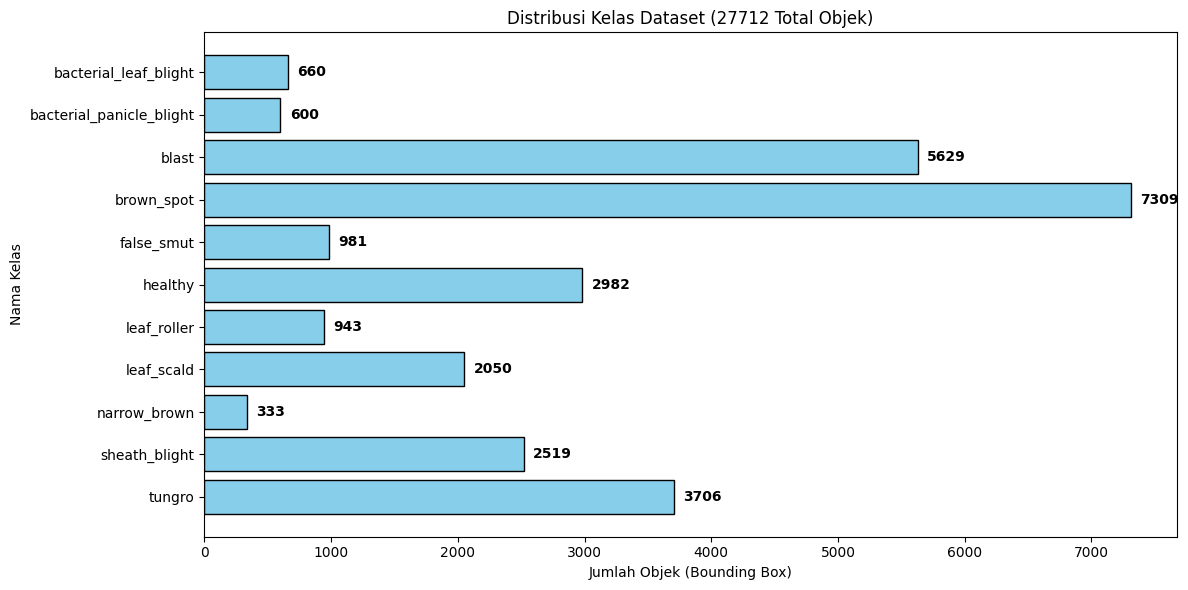

ID   | Nama Kategori             | Jumlah Objek | Persentase
------------------------------------------------------------
0    | bacterial_leaf_blight     | 660          | 2.38%
1    | bacterial_panicle_blight  | 600          | 2.17%
2    | blast                     | 5629         | 20.31%
3    | brown_spot                | 7309         | 26.37%
4    | false_smut                | 981          | 3.54%
5    | healthy                   | 2982         | 10.76%
6    | leaf_roller               | 943          | 3.40%
7    | leaf_scald                | 2050         | 7.40%
8    | narrow_brown              | 333          | 1.20%
9    | sheath_blight             | 2519         | 9.09%
10   | tungro                    | 3706         | 13.37%
------------------------------------------------------------


In [ ]:
from pathlib import Path
from collections import Counter
import yaml
import matplotlib.pyplot as plt

# 1. Tentukan lokasi file data.yaml
yaml_path = folder_tujuan / "dataset.yaml"

# 2. Baca file YAML 
with open(yaml_path, "r") as f:
    yaml_data = yaml.safe_load(f)

# Ambil informasi 'names' dan 'path' utama dari YAML
class_names = yaml_data.get("names", {})
base_path = Path(yaml_data.get("path", "."))

# lokasi folder labels (di dalam base_path)
labels_dir = base_path / "labels"

# 3. Hitung jumlah tiap class_id dari file label (.txt)
class_counts = Counter()
total_objects = 0

for txt_file in labels_dir.rglob("*.txt"):
    content = txt_file.read_text().strip()
    if not content:
        continue
    
    for line in content.splitlines():
        parts = line.split()
        if parts:
            cls_id = int(parts[0])
            class_counts[cls_id] += 1
            total_objects += 1

sorted_ids = sorted(class_names.keys())
labels = [class_names[i] for i in sorted_ids]
counts = [class_counts[i] for i in sorted_ids]

plt.figure(figsize=(12, 6))
bars = plt.barh(labels, counts, color='skyblue', edgecolor='black')

# Tambahkan angka/jumlah tepat di ujung tiap batang
for bar in bars:
    width = bar.get_width()
    plt.text(width + (max(counts) * 0.01 if counts and max(counts) > 0 else 1), 
             bar.get_y() + bar.get_height()/2, 
             f'{int(width)}', ha='left', va='center', fontweight='bold')

plt.xlabel('Jumlah Objek (Bounding Box)')
plt.ylabel('Nama Kelas')
plt.title(f'Distribusi Kelas Dataset ({total_objects} Total Objek)')
plt.gca().invert_yaxis()  # Agar ID 0 berada di paling atas
plt.tight_layout()
plt.show()

# 6. Tampilkan juga ringkasan tabel di terminal/log
print(f"{'ID':<4} | {'Nama Kategori':<25} | {'Jumlah Objek':<12} | {'Persentase'}")
print("-" * 60)
for i in sorted_ids:
    count = class_counts[i]
    pct = (count / total_objects * 100) if total_objects > 0 else 0
    print(f"{i:<4} | {class_names[i]:<25} | {count:<12} | {pct:.2f}%")
print("-" * 60)

## C2. Memvisualisasikan Anotasi

Mengambil sampel gambar train untuk setiap kelas, menggambar bounding box dari label YOLO, lalu menampilkan hasil anotasi dalam grid untuk inspeksi visual.

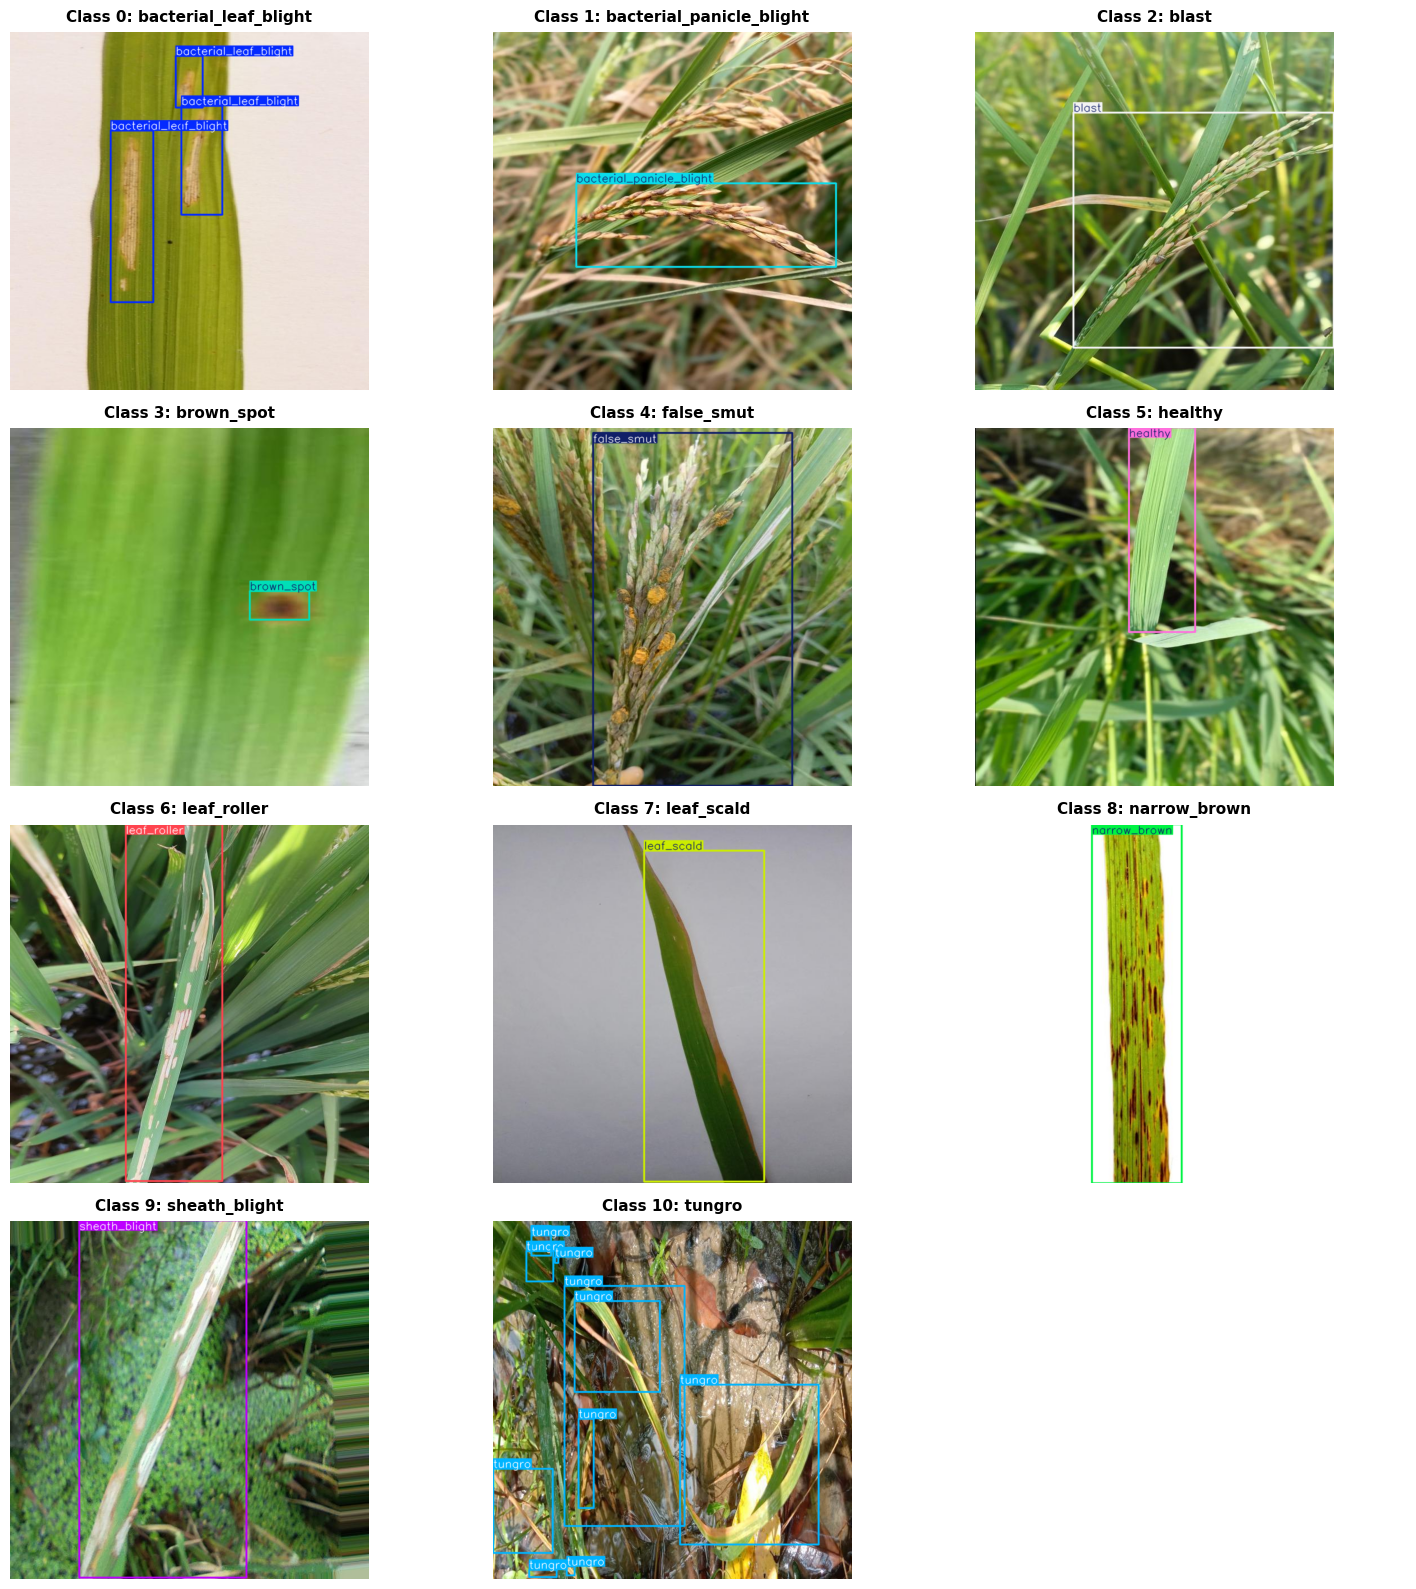

In [ ]:
import yaml
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics.utils.plotting import Annotator, colors

# 1. Read data.yaml
with open(yaml_path, "r") as f:
    data_yaml = yaml.safe_load(f)

base_path = Path(data_yaml.get("path", "."))
class_names = data_yaml.get("names", {})
images_dir = base_path / "images" / "train"
labels_dir = base_path / "labels" / "train"

# 2. Cari 1 sampel file untuk setiap kelas
sample_per_class = {}
for label_file in labels_dir.glob("*.txt"):
    if len(sample_per_class) == len(class_names):
        break  # Berhenti jika semua kelas sudah ditemukan sampelnya
    
    content = label_file.read_text().strip()
    if not content:
        continue

    # Cari file gambar yang cocok (.jpg, .png, .jpeg)
    img_file = next((images_dir / label_file.with_suffix(ext).name 
                     for ext in ['.jpg', '.png', '.jpeg', '.JPG', '.PNG'] 
                     if (images_dir / label_file.with_suffix(ext).name).exists()), None)
    if not img_file:
        continue

    for line in content.splitlines():
        parts = line.split()
        if len(parts) >= 5:
            cls_id = int(parts[0])
            if cls_id not in sample_per_class:
                sample_per_class[cls_id] = (img_file, label_file)

# 3. Setup Layout Grid Matplotlib (Atur 3 Kolom)
COLS = 3
sorted_ids = sorted(class_names.keys())
num_classes = len(sorted_ids)
ROWS = (num_classes + COLS - 1) // COLS  # Hitung jumlah baris otomatis

# Setting ukuran figur (lebar 15 inch, tinggi menyesuaikan jumlah baris)
fig, axes = plt.subplots(ROWS, COLS, figsize=(15, 4 * ROWS))
axes = axes.flatten() if num_classes > 1 else [axes]

# 4. Render Bounding Box Menggunakan Annotator Bawaan YOLO
for idx, cls_id in enumerate(sorted_ids):
    ax = axes[idx]
    
    if cls_id in sample_per_class:
        img_path, label_path = sample_per_class[cls_id]
        img = cv2.imread(str(img_path))
        h, w, _ = img.shape
        
        # Inisialisasi Annotator bawaan Ultralytics YOLO
        annotator = Annotator(img, line_width=2)

        # Gambar semua bounding box yang ada pada file label sampel
        for line in label_path.read_text().strip().splitlines():
            parts = line.split()
            if len(parts) >= 5:
                c_id = int(parts[0])
                # Convert koordinat YOLO ke Pixel Box
                box = [
                    (float(parts[1]) - float(parts[3]) / 2) * w,
                    (float(parts[2]) - float(parts[4]) / 2) * h,
                    (float(parts[1]) + float(parts[3]) / 2) * w,
                    (float(parts[2]) + float(parts[4]) / 2) * h,
                ]
                # Menggunakan pewarnaan otomatis khas YOLO berdasarkan class_id
                annotator.box_label(box, class_names[c_id], color=colors(c_id, True))

        # Konversi BGR OpenCV ke RGB Matplotlib
        annotated_img = cv2.cvtColor(annotator.result(), cv2.COLOR_BGR2RGB)
        
        ax.imshow(annotated_img)
        ax.set_title(f"Class {cls_id}: {class_names[cls_id]}", fontsize=11, fontweight='bold', pad=8)
    else:
        ax.text(0.5, 0.5, f"Tidak ada sampel untuk\nClass {cls_id}: {class_names[cls_id]}", 
                ha='center', va='center', color='red', fontsize=10)

    ax.axis('off')  # Sembunyikan sumbu X & Y

# Sembunyikan slot subplot sisa jika jumlah kelas bukan kelipatan 3
for i in range(num_classes, len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# D. Pelatihan Model

## D1. Melatih Model YOLO

Membuat model YOLO dari konfigurasi `yolo26l.yaml` dan melatihnya pada dataset dengan pengaturan epoch, ukuran gambar, batch, perangkat, augmentasi, serta early stopping.

In [ ]:
from ultralytics import YOLO
model = YOLO("yolo26l.yaml")
results = model.train(
    data=yaml_path, 
    epochs=300, 
    imgsz=640,
    pretrained=False,
    batch=32,
    device=[0,1],
    hsv_h=0.01,
    hsv_s=0.4,
    hsv_v=0.4,
    erasing=0.2,
    fliplr=0.3,
    flipud=0.0,
    mosaic=0.7,
    patience=30,
)

Ultralytics 8.4.177 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Dataset_Telepati/dataset.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.2, exist_ok=False, fliplr=0.3, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.4, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26l.yaml, momen

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      2/300      11.1G      3.296      5.938    0.06088         23        640: 100% ━━━━━━━━━━━━ 317/317 1.5it/s 3:38
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 1.9it/s 17.0s
                   all       2106       4887      0.257     0.0852     0.0412     0.0128

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      3/300      11.1G      2.541      3.916    0.04281         38        640: 100% ━━━━━━━━━━━━ 317/317 1.6it/s 3:23
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 1.9it/s 17.0s
                   all       2106       4887      0.319     0.0892     0.0145    0.00403

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      4/300      11.2G      2.252      3.508    0.03495         29        640: 100% ━━━━━━━━━

# E. Evaluasi Model

## E1. Mengevaluasi Model pada Data Test

Memuat bobot model terbaik, mengevaluasi performa pada split test, lalu mencetak metrik agregat dan AP50/F1 tiap kelas.

In [ ]:
model = YOLO("runs/detect/train/weights/best.pt")
m = model.val(data=yaml_path, split="test",imgsz=640)
b = m.box

print(f"mAP50    : {b.map50:.4f}")
print(f"mAP50-95 : {b.map:.4f}")
print(f"F1 (rata-rata kelas, di conf terbaik) : {b.f1.mean():.4f}")
print(f"F1 dari mean P dan R                  : {2*b.mp*b.mr/(b.mp+b.mr+1e-9):.4f}  (P={b.mp:.3f}, R={b.mr:.3f})")

for i, c in enumerate(b.ap_class_index):
    print(f"{m.names[c]:24s} AP50={b.ap50[i]:.3f}  F1={b.f1[i]:.3f}")

Ultralytics 8.4.177 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26l summary (fused): 188 layers, 24,754,221 parameters, 0 gradients, 86.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 11.8±6.4 MB/s, size: 37.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/working/Dataset_Telepati/labels/test... 1054 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1059/1059 1.0Kit/s 1.0s
val: New cache created: /kaggle/working/Dataset_Telepati/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 67/67 1.7it/s 38.4s
                   all       1059       2669      0.734      0.707      0.715      0.517
 bacterial_leaf_blight         29         59       0.47      0.481      0.396      0.189
bacterial_panicle_blight         27         27      0.958      0.851    

# F. Inferensi dan Visualisasi Prediksi

## F1. Menguji Prediksi pada Gambar Test

Memuat model terlatih dan memilih contoh gambar test untuk tiap kelas yang ditemukan. Model membuat prediksi pada gambar-gambar tersebut, kemudian hasil dengan bounding box ditampilkan.

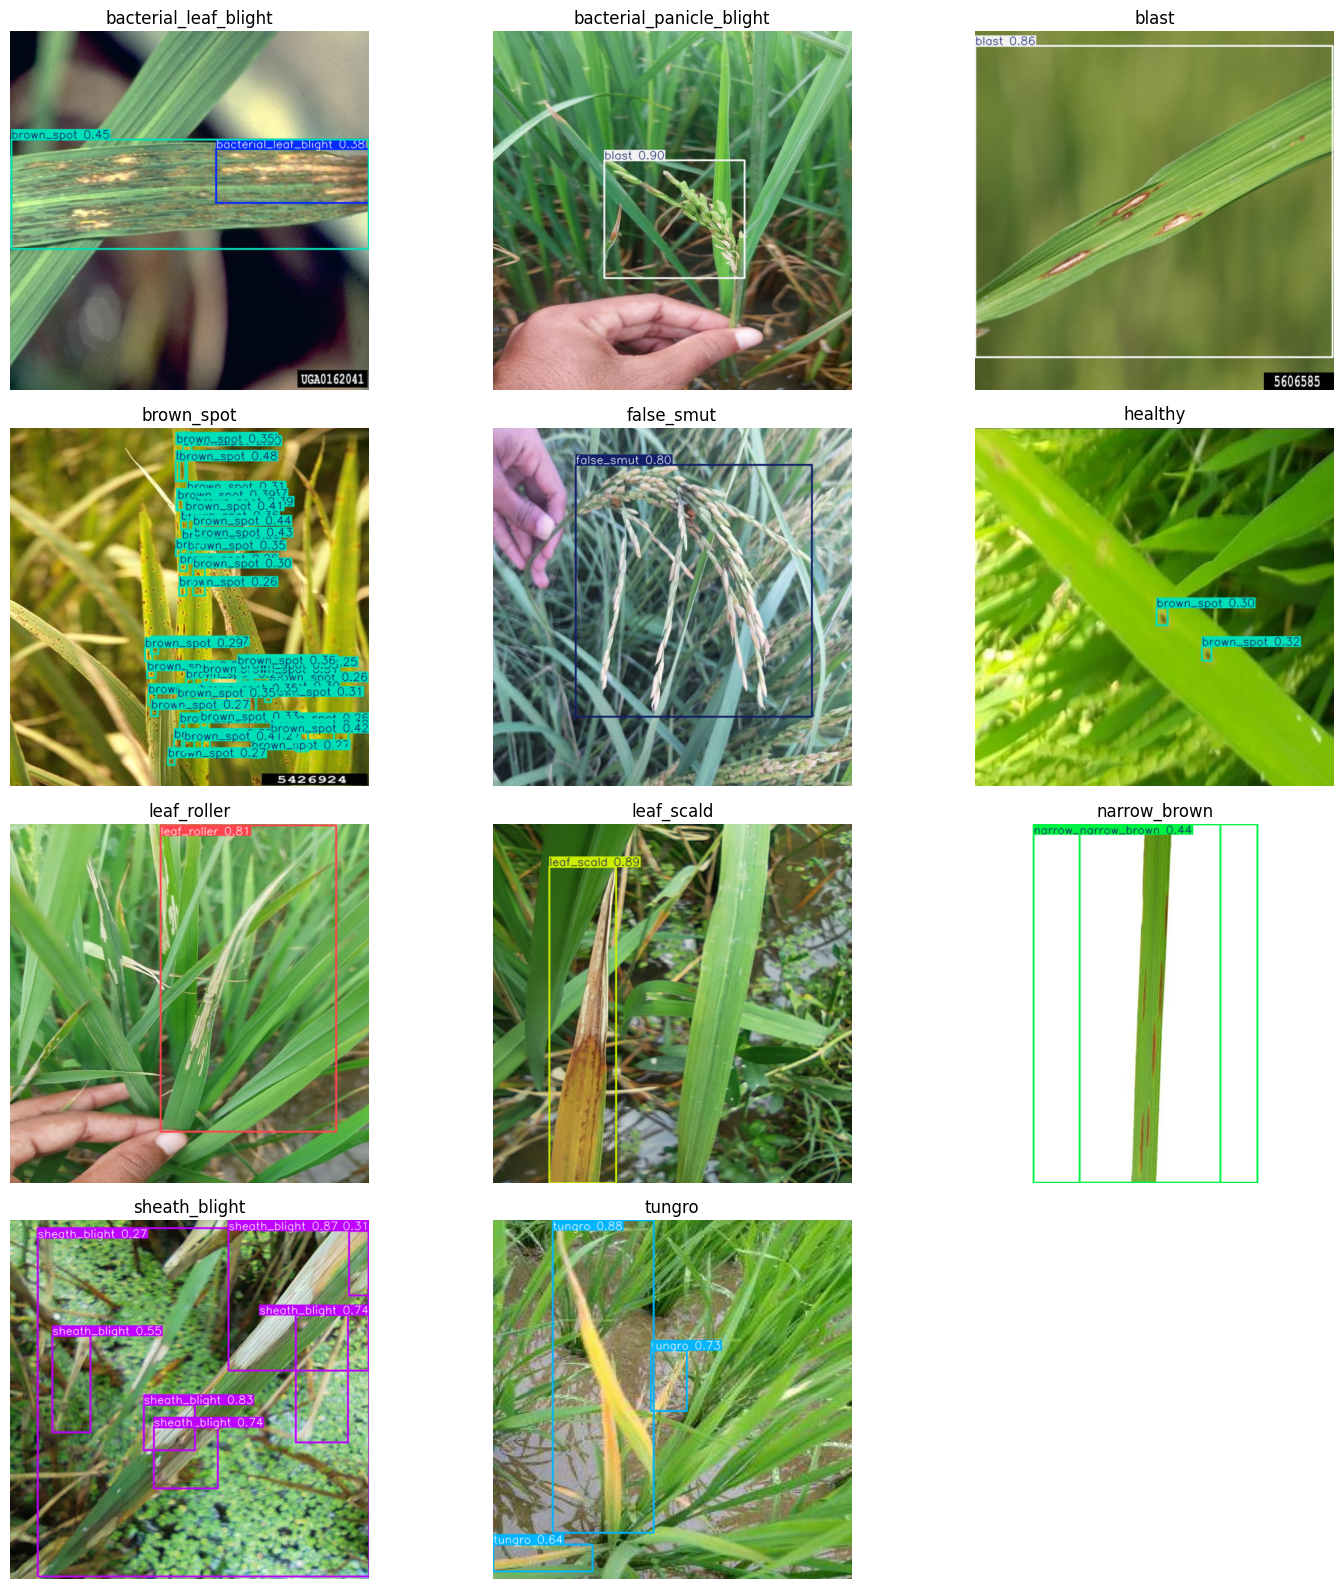

In [ ]:
import yaml
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

folder = folder_tujuan  # Pastikan sudah didefinisikan di cell sebelumnya.
with open(folder / "dataset.yaml", encoding="utf-8") as file:
    nama_kelas = yaml.safe_load(file)["names"]
model_final = YOLO("yolo26l_715.pt")  # Sesuaikan dengan lokasi weights.

# 1. Ambil satu gambar test untuk setiap kelas (berdasarkan file label)
contoh = {}
for label in sorted((folder / "labels/test").glob("*.txt")):
    for kelas in {int(baris.split()[0]) for baris in label.read_text().splitlines() if baris.strip()}:
        contoh.setdefault(kelas, label.stem)

# 2. Prediksi dan tampilkan
plt.figure(figsize=(15, 16))
for i, (kelas, nama_file) in enumerate(sorted(contoh.items())):
    gambar = next((folder / "images/test").glob(nama_file + ".*"))
    hasil = model_final.predict(gambar, conf=0.25, verbose=False)[0]
    plt.subplot(4, 3, i + 1)
    plt.imshow(hasil.plot()[..., ::-1])
    plt.title(nama_kelas[kelas])
    plt.axis("off")
plt.tight_layout()
plt.show()